In [1]:
#AI-Assisted Job Market Tracker: Data Analysis of German Job Postings Using Python, SQL, and Power BI
import pandas as pd

file_path = r"C:\Users\chith\Documents\Python work\german-job-postings.parquet"

df = pd.read_parquet(file_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (70584, 19)


,id,source,source_url,license,provenance,fetched_at,posted_date,lang,title,employer,description_derived,region,nuts_code,esco_occupation,esco_skills,is_green,kldb_2010,seniority,salary_range
0,10001-1003183488-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:37:00+00:00,2026-06-06,de,Betreuungskraft / Alltagsbegleiter/in (m/w/d),JB Arbeitsvermittlung,None,Schleswig-Holstein,DEF,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/486...,False,61212,unknown,None
1,10001-1003183486-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:37:00+00:00,2026-06-06,de,Gesundheits- und Pflegeassistent/in - GPA (m/w/d),JB Arbeitsvermittlung,None,Niedersachsen,DE9,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/280...,False,72122,unknown,None
2,10001-1003183484-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:37:00+00:00,2026-06-06,de,"Qualitätsbeauftragter - QMB, QB für zentrales ...",JB Arbeitsvermittlung,None,Hamburg,DE6,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/ae9...,False,61394,unknown,None
3,10001-1003183482-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:37:00+00:00,2026-06-06,de,Koch / Köchin für eine Seniorenresidenz (m/w/d),JB Arbeitsvermittlung,None,Berlin,DE3,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/538...,False,32152,unknown,None
4,10001-1003183481-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:37:00+00:00,2026-06-06,de,"Nette/r Hotelfachfrau/mann, Servicemitarbeiter...",JB Arbeitsvermittlung,None,Hessen,DE7,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/8c8...,False,51412,unknown,None


In [2]:

print("Dataset size:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nExample job titles:")
print(df["title"].head(10).to_string(index=False))

print("\nExample regions:")
print(df["region"].value_counts().head(10))

print("\nExample skill data:")
print(df["esco_skills"].head(3).to_string())

Dataset size: (70584, 19)

Missing values:
description_derived    70584
salary_range           69330
nuts_code                473
kldb_2010                136
region                   113
employer                  41
esco_occupation            4
posted_date                0
lang                       0
title                      0
source                     0
fetched_at                 0
provenance                 0
license                    0
esco_skills                0
is_green                   0
source_url                 0
seniority                  0
id                         0
dtype: int64

Example job titles:
     Betreuungskraft / Alltagsbegleiter/in (m/w/d)
 Gesundheits- und Pflegeassistent/in - GPA (m/w/d)
Qualitätsbeauftragter - QMB, QB für zentrales Q...
   Koch / Köchin für eine Seniorenresidenz (m/w/d)
Nette/r Hotelfachfrau/mann, Servicemitarbeiter/...
Servicekraft (m/w/d) für Spielhalle / Spielcasi...
   Lohnbuchhalter/in, Gehaltsbuchhalter/in (m/w/d)
Qualitätsbeauft

In [3]:
# Search for relevant data and analytics job titles

keywords = [
    "data analyst",
    "datenanalyst",
    "business intelligence",
    "business analyst",
    "bi analyst",
    "power bi",
    "reporting analyst",
    "data scientist",
    "data engineer",
    "controller"
]

pattern = "|".join(keywords)

data_jobs = df[
    df["title"].str.contains(
        pattern,
        case=False,
        na=False,
        regex=True
    )
].copy()

print("Matching job postings:", len(data_jobs))

print("\nJob titles found:")
print(data_jobs["title"].value_counts().head(30).to_string())

Matching job postings: 766

Job titles found:
title
Data Engineer                                                              30
Controller (m/w/d)                                                         28
Data Engineer (m/w/d)                                                      26
Data Scientist (m/w/d)                                                     21
Data Analyst (m/w/d)                                                       20
Data Scientist                                                             19
Data Engineer (w/m/d)                                                       7
Business Analyst (m/w/d)                                                    5
Senior Controller (m/w/d)                                                   5
Senior Data Engineer (m/w/d)                                                4
Projektcontroller (m/w/d)                                                   4
Senior Data Analyst (m/w/d)                                                 3
Data Analyst

In [4]:
#check whether the dataset has Munich jobs
print("Bavaria job postings:")
print((df["region"] == "Bayern").sum())

print("\nMunich-related job titles and locations:")
munich_jobs = df[
    df["region"].eq("Bayern")
    & df["title"].str.contains(
        pattern,
        case=False,
        na=False,
        regex=True
    )
]

print("Matching postings in Bavaria:", len(munich_jobs))
print(munich_jobs[["title", "employer", "region", "posted_date"]]
      .head(20).to_string(index=False))

Bavaria job postings:
10205

Munich-related job titles and locations:
Matching postings in Bavaria: 108
                                                               title                                                employer region posted_date
                                       Senior Controller F&B (m/w/d)                                   Hotel Bayerischer Hof Bayern  2026-06-01
                                        Senior Controller HR (m/w/d)                                   Hotel Bayerischer Hof Bayern  2026-06-01
                                      Technischer Controller (m/w/d)                                   Hotel Bayerischer Hof Bayern  2026-06-01
                         Business Analyst (m/w/d) Lebensversicherung                                 ROSA Experts AG & Co KG Bayern  2026-06-05
                                                  Controller (m/w/d)                                          Iventa Austria Bayern  2026-06-05
                                

In [6]:
#Check skills column
print("Data type of first skills value:")
print(type(df["esco_skills"].iloc[0]))

print("\nExample skills value:")
print(df["esco_skills"].iloc[0])


Data type of first skills value:
<class 'numpy.ndarray'>

Example skills value:
[{'uri': 'http://data.europa.eu/esco/skill/486df8bc-3498-43ad-83b6-dc8a4a3b16c6', 'label': 'provide support to social services users'}
 {'uri': 'http://data.europa.eu/esco/skill/36fe44b2-af36-4467-9be8-601e64b3dbc7', 'label': 'liaise with educational support staff'}
 {'uri': 'http://data.europa.eu/esco/skill/fb9c12af-ec45-498a-8e52-891371191557', 'label': 'mentor individual employees'}
 {'uri': 'http://data.europa.eu/esco/skill/ab89ad86-1098-44bb-9465-05af5624557c', 'label': 'accompany people'}
 {'uri': 'http://data.europa.eu/esco/skill/968ae7d9-40ca-4593-8dc6-fac11e4eeb6b', 'label': 'supervise forestry workers'}]


In [5]:
#Extract skill names

def extract_skill_labels(skills):
    if skills is None:
        return []

    labels = []
    for skill in skills:
        if isinstance(skill, dict) and skill.get("label"):
            labels.append(skill["label"])

    return labels

df["skill_labels"] = df["esco_skills"].apply(extract_skill_labels)

print(df["skill_labels"].iloc[0])


['provide support to social services users', 'liaise with educational support staff', 'mentor individual employees', 'accompany people', 'supervise forestry workers']


In [9]:

from collections import Counter
import pandas as pd

# Step 1: Filter analyst-related job titles
target_pattern = (
    r"data analyst|datenanalyst|business intelligence|"
    r"bi analyst|business analyst|reporting analyst"
)

target_jobs = df[
    df["title"].str.contains(
        target_pattern,
        case=False,
        na=False,
        regex=True
    )
].copy()

# Step 2: Count skills in the filtered job postings
analyst_skill_counts = Counter(
    skill
    for skills in target_jobs["skill_labels"]
    for skill in skills
)

# Step 3: Display the 20 most frequent skills
analyst_top_skills = pd.DataFrame(
    analyst_skill_counts.most_common(20),
    columns=["Skill", "Frequency"]
)

print("Matching analyst postings:", len(target_jobs))
print("\nTop skills in analyst postings:")
print(analyst_top_skills.to_string(index=False))


Matching analyst postings: 234

Top skills in analyst postings:
                                     Skill  Frequency
                     perform data analysis        103
              perform safety data analysis         80
                         business analysis         76
                analyse data about clients         72
                    carry out job analysis         70
               perform occupation analyses         69
                analyse business processes         55
                     business intelligence         36
                        business analytics         26
                    analyse business plans         26
             analyse information processes         20
                 oversee record management         20
              perform online data analysis         17
                 perform business analysis         16
          analyse customer service surveys         15
                              process data         14
analyse financial 

In [10]:
#Analyse skills for Data Analyst and Business Analyst roles
#Analyse job seniority

print("Seniority distribution for analyst-related postings:")
print(target_jobs["seniority"].value_counts(dropna=False).to_string())

print("\nJob titles by seniority:")
print(
    target_jobs.groupby(
        ["seniority", "title"],
        dropna=False
    ).size().to_string()
)


Seniority distribution for analyst-related postings:
seniority
unknown    196
senior      16
junior      10
entry        9
lead         3

Job titles by seniority:
seniority  title                                                                                               
entry      EY-Parthenon Praktikant Data Analyst - Strategy and Transactions (w/m/d)                                 1
           Intern Data Engineering & Business Intelligence in Financial Services (f/m/x)                            1
           Internship Global Sales Performance and Business Intelligence                                            1
           Praktikant / Data Analyst Business Development / Intelligence (m/w/d)                                    1
           Praktikant Business Intelligence im Umfeld Data Analytics (w/m/x)                                        1
           Praktikant Business Intelligence, Data und Analytics (m/w/d) in Düsseldorf                               1
           Prakt

In [11]:

# Filter junior and entry-level analyst postings

junior_jobs = target_jobs[
    target_jobs["seniority"].isin(["junior", "entry"])
].copy()

print("Junior and entry-level postings:", len(junior_jobs))

print("\nJob titles:")
print(
    junior_jobs[
        ["title", "employer", "region", "posted_date", "seniority"]
    ].sort_values(
        ["seniority", "title"]
    ).to_string(index=False)
)

print("\nJunior and entry-level postings by region:")
print(junior_jobs["region"].value_counts().head(10).to_string())


Junior and entry-level postings: 19

Job titles:
                                                                            title                         employer              region posted_date seniority
         EY-Parthenon Praktikant Data Analyst - Strategy and Transactions (w/m/d)  EY Strategy & Transactions GmbH              Berlin  2026-03-11     entry
    Intern Data Engineering & Business Intelligence in Financial Services (f/m/x)                           BMW AG              Bayern  2026-04-28     entry
                    Internship Global Sales Performance and Business Intelligence            Deutsche Lufthansa AG              Hessen  2026-04-28     entry
            Praktikant / Data Analyst Business Development / Intelligence (m/w/d)                   Rheinmetall AG              Bremen  2026-01-27     entry
                Praktikant Business Intelligence im Umfeld Data Analytics (w/m/x)                           BMW AG             Sachsen  2026-06-04     entry
       Pr

In [12]:
#Find relevant junior roles with unknown seniority

junior_title_pattern = r"junior|\(junior\)|entry.level"

junior_title_jobs = target_jobs[
    target_jobs["title"].str.contains(
        junior_title_pattern,
        case=False,
        na=False,
        regex=True
    )
].copy()

print("Jobs with junior/entry-level wording:", len(junior_title_jobs))

print("\nResults in Bavaria:")
bavaria_junior_titles = junior_title_jobs[
    junior_title_jobs["region"].eq("Bayern")
]

print(
    bavaria_junior_titles[
        ["title", "employer", "posted_date", "seniority"]
    ].to_string(index=False)
)

print("\nAll matching titles and locations:")
print(
    junior_title_jobs[
        ["title", "employer", "region", "posted_date", "seniority"]
    ].to_string(index=False)
)


Jobs with junior/entry-level wording: 10

Results in Bavaria:
Empty DataFrame
Columns: [title, employer, posted_date, seniority]
Index: []

All matching titles and locations:
                                                                            title                         employer              region posted_date seniority
                                Junior Business Analyst Energiewirtschaft (m/w/d) CBC Cologne Business Center GmbH Nordrhein-Westfalen  2026-06-05    junior
                              (Junior) Data Analyst - Schwerpunkt Finance (m/w/d)        Schrade Kabeltechnik GmbH   Baden-Württemberg  2026-05-13    junior
                                                    (Junior) Data Analyst (w/m/d)                   MSR Consulting Nordrhein-Westfalen  2026-04-15    junior
                                     (Junior) Data Analyst (m/w/d) Data Analytics                         Syncwork              Berlin  2026-05-16    junior
                                     (Ju

In [13]:
#Analyze job posting dates

# Convert posting dates into datetime format
target_jobs["posted_date"] = pd.to_datetime(
    target_jobs["posted_date"],
    errors="coerce"
)

# Remove rows where the posting date is missing
dated_jobs = target_jobs.dropna(subset=["posted_date"]).copy()

# Extract year and month
dated_jobs["posting_month"] = (
    dated_jobs["posted_date"].dt.to_period("M").astype(str)
)

# Count postings by month
monthly_postings = (
    dated_jobs.groupby("posting_month")
    .size()
    .reset_index(name="Number_of_Postings")
    .sort_values("posting_month")
)

print("Date range:")
print(dated_jobs["posted_date"].min(), "to", dated_jobs["posted_date"].max())

print("\nMonthly postings:")
print(monthly_postings.to_string(index=False))


Date range:
2022-12-28 00:00:00 to 2026-06-05 00:00:00

Monthly postings:
posting_month  Number_of_Postings
      2022-12                   1
      2024-02                   1
      2024-06                   1
      2025-02                   2
      2025-03                   2
      2025-05                   1
      2025-06                   1
      2025-08                   3
      2025-09                   2
      2025-10                   1
      2025-11                   5
      2025-12                   5
      2026-01                   5
      2026-02                   3
      2026-03                  24
      2026-04                  43
      2026-05                  84
      2026-06                  50


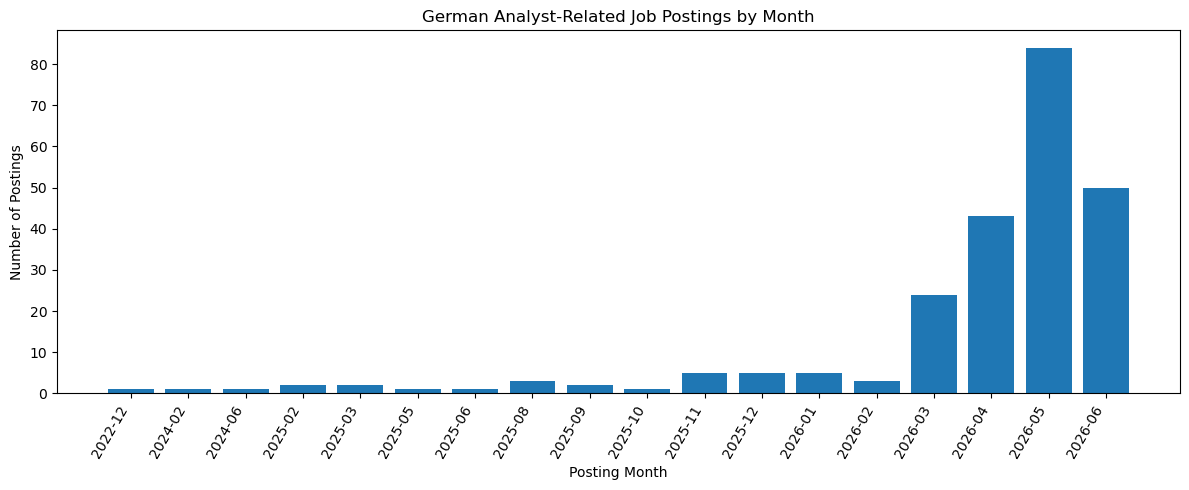

In [14]:
#visualise the monthly posting counts

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_postings["posting_month"],
    monthly_postings["Number_of_Postings"]
)

plt.title("German Analyst-Related Job Postings by Month")
plt.xlabel("Posting Month")
plt.ylabel("Number of Postings")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
#Save filtered analyst job postings
target_jobs.to_csv(
    "analyst_job_postings.csv",
    index=False
)

# Save the monthly posting summary
monthly_postings.to_csv(
    "monthly_posting_summary.csv",
    index=False
)

print("Files saved successfully:")
print("1. analyst_job_postings.csv")
print("2. monthly_posting_summary.csv")


In [15]:
# Save the analyzed result as csv

# Set output folder
output_folder = r"C:\Users\chith\Documents\Python work"

# Save the filtered analyst job postings
target_jobs.to_csv(
    output_folder + r"\analyst_job_postings.csv",
    index=False
)

# Save the monthly posting summary
monthly_postings.to_csv(
    output_folder + r"\monthly_posting_summary.csv",
    index=False
)

print("Files saved successfully:")
print(output_folder + r"\analyst_job_postings.csv")
print(output_folder + r"\monthly_posting_summary.csv")


Files saved successfully:
C:\Users\chith\Documents\Python work\analyst_job_postings.csv
C:\Users\chith\Documents\Python work\monthly_posting_summary.csv


In [16]:
#Load and Clean Dataset


import pandas as pd

file_path = r"C:\Users\chith\Documents\Python work\analyst_job_postings.csv"

jobs = pd.read_csv(file_path)

print("Number of rows:", jobs.shape[0])
print("Number of columns:", jobs.shape[1])
print("\nColumn names:")
print(jobs.columns.tolist())

print("\nFirst 5 rows:")
display(jobs.head())


Number of rows: 234
Number of columns: 20

Column names:
['id', 'source', 'source_url', 'license', 'provenance', 'fetched_at', 'posted_date', 'lang', 'title', 'employer', 'description_derived', 'region', 'nuts_code', 'esco_occupation', 'esco_skills', 'is_green', 'kldb_2010', 'seniority', 'salary_range', 'skill_labels']

First 5 rows:


,id,source,source_url,license,provenance,fetched_at,posted_date,lang,title,employer,description_derived,region,nuts_code,esco_occupation,esco_skills,is_green,kldb_2010,seniority,salary_range,skill_labels
0,12942-1565433-2-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:37:00+00:00,2026-06-05,de,Business Analyst (m/w/d) im Bereich Data,Dirk Rossmann GmbH,NaN,Niedersachsen,DE9,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/633...,False,43103,unknown,NaN,"['business analysis', 'analyse data about clie..."
1,10001-1003143472-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:38:40+00:00,2026-05-28,de,B114-C04 Business Analyst (m/w/d),Jan Schreiner Private Arbeitsvermittlung Arbitex,NaN,Nordrhein-Westfalen,DEA,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/633...,False,43103,unknown,NaN,"['business analysis', 'analyse business plans'..."
2,11956-2976001780092001-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:38:40+00:00,2026-05-30,de,CENDAS GmbH: Business Analyst / (UX-)Consultan...,CENDAS GmbH,NaN,Nordrhein-Westfalen,DEA,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/988...,False,43103,unknown,NaN,['use customer relationship management softwar...
3,12362-TR-288153_612308LS-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:38:34+00:00,2026-06-01,de,Data Analyst (w/m/d),Brunel GmbH NL Duisburg,NaN,Nordrhein-Westfalen,DEA,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/2b9...,False,43103,unknown,NaN,"['perform data analysis', 'carry out job analy..."
4,12288-4835090067-S,bundesagentur,https://www.arbeitsagentur.de/jobsuche/jobdeta...,CC-BY-4.0,normalized from bundesagentur jobsuche API v4 ...,2026-06-06 01:38:34+00:00,2026-06-01,de,Business Intelligence Entwickler (m/w/d),hyrUP GmbH,NaN,Nordrhein-Westfalen,DEA,{'uri': 'http://data.europa.eu/esco/occupation...,[{'uri': 'http://data.europa.eu/esco/skill/143...,False,43103,unknown,NaN,"['business intelligence', 'business analytics'..."


In [17]:
# Clean for SQL and Pwer BI
import pandas as pd
import ast
import os

# Project folder
output_folder = r"C:\Users\chith\Documents\Python work"

# Load the saved analyst job postings
file_path = os.path.join(
    output_folder,
    "analyst_job_postings.csv"
)

jobs = pd.read_csv(file_path)

# Select useful columns for job market analysis
job_columns = [
    "id",
    "title",
    "employer",
    "region",
    "posted_date",
    "seniority",
    "salary_range",
    "source",
    "source_url"
]

jobs_clean = jobs[job_columns].copy()

# Clean text columns
for column in ["title", "employer", "region", "seniority"]:
    jobs_clean[column] = jobs_clean[column].fillna("Unknown").astype(str).str.strip()

# Convert posting date to a consistent date format
jobs_clean["posted_date"] = pd.to_datetime(
    jobs_clean["posted_date"],
    errors="coerce"
)

# Save the clean job postings dataset
jobs_clean.to_csv(
    os.path.join(output_folder, "analyst_job_postings_clean.csv"),
    index=False
)

# Convert the skill-label column into a list
def parse_skills(value):
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

jobs["skill_labels"] = jobs["skill_labels"].apply(parse_skills)

# Create one row per job and skill
skill_rows = []

for _, row in jobs.iterrows():
    for skill in row["skill_labels"]:
        skill_rows.append({
            "job_id": row["id"],
            "job_title": row["title"],
            "region": row["region"],
            "seniority": row["seniority"],
            "skill": skill
        })

skills_clean = pd.DataFrame(
    skill_rows,
    columns=["job_id", "job_title", "region", "seniority", "skill"]
)

skills_clean.to_csv(
    os.path.join(output_folder, "analyst_job_skills.csv"),
    index=False
)

print("Datasets created successfully!")
print("Clean job postings:", jobs_clean.shape)
print("Job skills:", skills_clean.shape)
print("\nTop 10 skills:")
print(skills_clean["skill"].value_counts().head(10))


Datasets created successfully!
Clean job postings: (234, 9)
Job skills: (1170, 5)

Top 10 skills:
skill
perform data analysis           103
perform safety data analysis     80
business analysis                76
analyse data about clients       72
carry out job analysis           70
perform occupation analyses      69
analyse business processes       55
business intelligence            36
business analytics               26
analyse business plans           26
Name: count, dtype: int64


TOP 10 REGIONS


,Region,Number_of_Postings
0,Nordrhein-Westfalen,56
1,Hessen,41
2,Baden-Württemberg,27
3,Bayern,24
4,Hamburg,22
5,Niedersachsen,21
6,Berlin,17
7,Sachsen,12
8,Mecklenburg-Vorpommern,4
9,Unknown,3


POSTINGS BY SENIORITY


,Seniority,Number_of_Postings
0,unknown,196
1,senior,16
2,junior,10
3,entry,9
4,lead,3


TOP 10 EMPLOYERS


,Employer,Number_of_Postings
0,Finanz Informatik GmbH & Co. KG,12
1,Hays Professional Solutions GmbH,5
2,Deloitte GmbH,3
3,Rheinmetall AG,3
4,DGL Services GmbH,3
5,AOK Systems GmbH,3
6,Dirk Rossmann GmbH,2
7,ZOLL CMS GmbH,2
8,ALDI Einkauf SE & Co. OHG,2
9,Vodafone GmbH,2


MONTHLY POSTINGS


,Month,Number_of_Postings
0,2022-12,1
1,2024-02,1
2,2024-06,1
3,2025-02,2
4,2025-03,2
5,2025-05,1
6,2025-06,1
7,2025-08,3
8,2025-09,2
9,2025-10,1


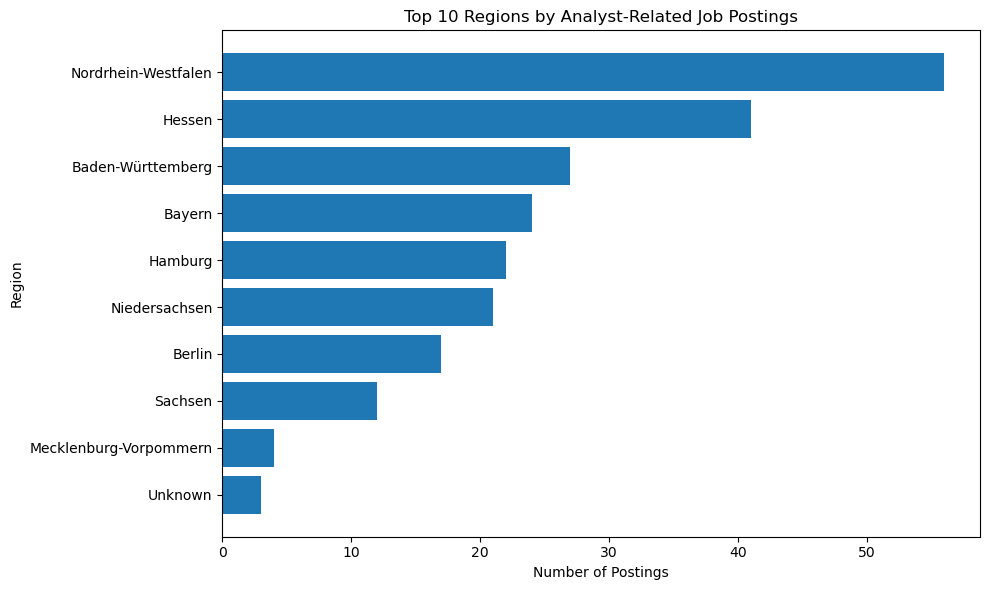

In [18]:
#Analyse the German job market using Python
import pandas as pd
import matplotlib.pyplot as plt
import os

output_folder = r"C:\Users\chith\Documents\Python work"

# Load the clean datasets
jobs = pd.read_csv(
    os.path.join(output_folder, "analyst_job_postings_clean.csv")
)

skills = pd.read_csv(
    os.path.join(output_folder, "analyst_job_skills.csv")
)

# 1. Postings by region
region_counts = (
    jobs["region"]
    .value_counts()
    .reset_index()
)
region_counts.columns = ["Region", "Number_of_Postings"]

print("TOP 10 REGIONS")
display(region_counts.head(10))

# 2. Postings by seniority
seniority_counts = (
    jobs["seniority"]
    .value_counts()
    .reset_index()
)
seniority_counts.columns = ["Seniority", "Number_of_Postings"]

print("POSTINGS BY SENIORITY")
display(seniority_counts)

# 3. Employers with the most postings
employer_counts = (
    jobs["employer"]
    .value_counts()
    .head(10)
    .reset_index()
)
employer_counts.columns = ["Employer", "Number_of_Postings"]

print("TOP 10 EMPLOYERS")
display(employer_counts)

# 4. Postings by month
jobs["posted_date"] = pd.to_datetime(
    jobs["posted_date"], errors="coerce"
)

monthly_counts = (
    jobs.dropna(subset=["posted_date"])
    .assign(Month=lambda x: x["posted_date"].dt.to_period("M").astype(str))
    .groupby("Month")
    .size()
    .reset_index(name="Number_of_Postings")
    .sort_values("Month")
)

print("MONTHLY POSTINGS")
display(monthly_counts)

# Save summary tables for Power BI
region_counts.to_csv(
    os.path.join(output_folder, "region_summary.csv"), index=False
)
seniority_counts.to_csv(
    os.path.join(output_folder, "seniority_summary.csv"), index=False
)
employer_counts.to_csv(
    os.path.join(output_folder, "employer_summary.csv"), index=False
)
monthly_counts.to_csv(
    os.path.join(output_folder, "monthly_summary.csv"), index=False
)

# Visualise the top 10 regions
top_regions = region_counts.head(10).sort_values(
    "Number_of_Postings"
)

plt.figure(figsize=(10, 6))
plt.barh(top_regions["Region"], top_regions["Number_of_Postings"])
plt.title("Top 10 Regions by Analyst-Related Job Postings")
plt.xlabel("Number of Postings")
plt.ylabel("Region")
plt.tight_layout()
plt.show()
